In [18]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.processing.vectorize import input_to_tensor
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [85]:
device = 'cuda:0'
model = create_multimodal_perceiver(cf, device)
states = {}
for i in range(4):
            states['observation_'+str(i)] = torch.ones(24, 1, 1, device=device)
x = input_to_tensor(states, model.modality, cf.body_parts).to(device)
memories = create_memories(model, cf.num_envs, device=device, 
                            mem_size=cf.mem_size, cmem_size=cf.cmem_size)

In [66]:
y, _, _ = model(x, memories, queries=model.queries)
output = output_projection(model, x, cf.body_outputs, 
                          1, cf.audio_future)

In [67]:
for key in output.keys():
    print(key, output[key].shape)

action_0 torch.Size([24, 1, 1])
action_variance_0 torch.Size([24, 1, 1])
critic torch.Size([24, 1, 1])


In [75]:
loss_all = []

In [80]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [81]:
for i in range(100000):
    tmp = torch.zeros(24, 1, 1, device=device)
    for i in range(4):
        tmp_i = torch.rand(24, 1, 1, device=device)
        tmp += tmp_i
        states['observation_'+str(i)] = tmp_i
    y_target =  tmp.detach()

    x = input_to_tensor(states, model.modality, cf.body_parts).to(device)
    memories = create_memories(model, cf.num_envs, device=device, 
                                mem_size=cf.mem_size, cmem_size=cf.cmem_size)
    y, _, _ = model(x, memories, queries=model.queries)
    output = output_projection(model, x, cf.body_outputs, 
                            1, cf.audio_future)
    print('std', output['action_0'].std().item())

    loss = F.mse_loss(output['action_0'], y_target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # with torch.no_grad():  # No tracking of gradients during the update
    #     for param in model.parameters():
    #         if param.grad is not None:
    #             param -= 1e-4 * param.grad
    loss_all.append(loss.item())
    print(loss.item())

std 0.0061615523882210255
5.430577278137207
std 0.006221500691026449
6.120053768157959
std 0.005398925393819809
5.491168975830078
std 0.005179805681109428
5.320728302001953
std 0.00538975466042757
5.660293102264404
std 0.005862222518771887
4.986409664154053
std 0.0040856399573385715
4.359893798828125
std 0.005476437509059906
4.409093856811523
std 0.005802540108561516
3.84120512008667
std 0.004864128772169352
3.6026649475097656
std 0.004659703467041254
2.8471171855926514
std 0.005590218119323254
3.4299657344818115
std 0.005152507685124874
2.834476947784424
std 0.005801184102892876
3.5700318813323975
std 0.004593452904373407
3.342869520187378
std 0.004616220481693745
1.9926345348358154
std 0.0059493957087397575
2.705832004547119
std 0.005433857906609774
2.503406524658203
std 0.0057755885645747185
1.7596373558044434
std 0.005138608161360025
1.861466407775879
std 0.0060786958783864975
1.9589614868164062
std 0.004884648602455854
1.424246072769165
std 0.004736372269690037
1.4375355243682861


KeyboardInterrupt: 

In [44]:
from matplotlib import pyplot as plt

In [82]:
print(y_target[:3])

tensor([[[1.1956]],

        [[2.0402]],

        [[1.9443]]], device='cuda:0')


In [83]:
print(output['action_0'][:3])

tensor([[[1.8419]],

        [[1.8523]],

        [[1.8787]]], device='cuda:0', grad_fn=<SliceBackward0>)


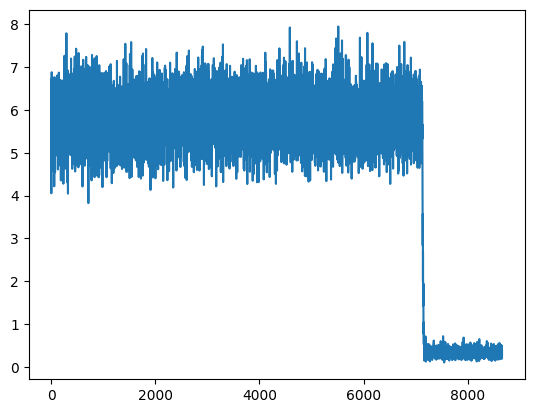

In [84]:
plt.plot(loss_all)